In [3]:
import plotly 
import kaleido  
import IPython 
import pandas as pd

ModuleNotFoundError: No module named 'pandas'

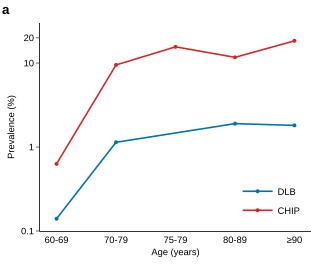

In [33]:
import numpy as np
import plotly.graph_objects as go

FONT = "Arial"
TEXT_PT, AXIS_PT, LETTER_PT = 7.0, 7.0, 10.0
AXIS_LINE_PT, TICK_LENGTH_PT = 0.6, 2.5

PT_MM_ = globals().get("PT_MM", 25.4 / 72)
U_ = globals().get("U", 96 / 25.4)
HEADER_MM = globals().get("HEADER", 6.0)

TEXT = TEXT_PT * PT_MM_ * U_
AXIS_TEXT = AXIS_PT * PT_MM_ * U_
LETTER = LETTER_PT * PT_MM_ * U_
AXIS_LINE = AXIS_LINE_PT * PT_MM_ * U_
TICK_LENGTH = TICK_LENGTH_PT * PT_MM_ * U_

W_MM, H_MM = 170.0 / 2, 70.0
W, H = round(W_MM * U_), round(H_MM * U_)
ML, MR, MT, MB = 40, 10, round(HEADER_MM * U_), 34

ages = ["60-69", "70-79", "75-79", "80-89", "≥90"]
dlb = [0.14, 1.14, None, 1.9, 1.81]
chip = [0.63, 9.5, 15.6, 11.7, 18.4]

fig = go.Figure()
for name, y, col in [("DLB", dlb, "#0072B2"), ("CHIP", chip, "#D62728")]:
    fig.add_trace(go.Scatter(
        x=ages, y=y, name=name, mode="lines+markers", connectgaps=True,
        line=dict(color=col, width=AXIS_LINE * 2), marker=dict(color=col, size=4),
        hoverinfo="skip",
    ))

pw, ph = W - ML - MR, H - MT - MB

fig.update_layout(
    width=W, height=H, title=None,
    font=dict(family=FONT, size=TEXT, color="black"),
    paper_bgcolor="white", plot_bgcolor="white",
    margin=dict(l=ML, r=MR, t=MT, b=MB),
    showlegend=True,
    legend=dict(x=0.98, y=0.03, xanchor="right", yanchor="bottom",
                bgcolor="rgba(0,0,0,0)", borderwidth=0,
                itemwidth=30, tracegroupgap=0,
                font=dict(family=FONT, size=TEXT)),
    hovermode=False, dragmode=False,
    annotations=[dict(
        text="<b>a</b>", xref="paper", yref="paper",
        x=-ML / pw, y=1 + MT / ph, xanchor="left", yanchor="top",
        showarrow=False, font=dict(family=FONT, size=LETTER, color="black"),
    )],
)

common = dict(
    showline=True, linecolor="black", linewidth=AXIS_LINE,
    tickwidth=AXIS_LINE, ticklen=TICK_LENGTH, showgrid=False, fixedrange=True,
    title_standoff=4,
    title_font=dict(family=FONT, size=AXIS_TEXT, color="black"),
    tickfont=dict(family=FONT, size=TEXT, color="black"),
)

fig.update_xaxes(title_text="Age (years)", type="category",
                 categoryorder="array", categoryarray=ages, ticks="", **common)
fig.update_yaxes(title_text="Prevalence (%)", type="log",
                 range=[np.log10(0.1), np.log10(30)],
                 tickvals=[0.1, 1, 10, 20], ticktext=["0.1", "1", "10", "20"],
                 ticks="outside", **common)

try:
    from IPython.display import display, SVG
    display(SVG(data=fig.to_image(format="svg")))
except Exception:
    fig.show(config={"staticPlot": True, "displayModeBar": False})

In [34]:
from pathlib import Path

out_dir = Path("/mnt/claw-raid/elliot/P001_CHIP/Results")
out_dir.mkdir(parents=True, exist_ok=True)

svg_path = out_dir / "panel_a_DLB_CHIP_prevalence.svg"
fig.write_image(str(svg_path), format="svg", width=W, height=H)

if not svg_path.is_file() or svg_path.stat().st_size == 0:
    raise RuntimeError("SVG was not saved.")
print(f"Saved: {svg_path}")

Saved: /mnt/claw-raid/elliot/P001_CHIP/Results/panel_a_DLB_CHIP_prevalence.svg
